# 05 | Predictive Modeling

## Table of Contents

1. Data Preparation and Preprocessing
2. Training and Testing Split
3. Logistic Regression
4. Random Forest
5. Feature Importance
6. Final Model Evaluation and Overfitting Check
7. Random Forest Overfitting Reduction
8. Cross-Validation and Model Selection
9. Credit Risk Predictions for New Borrowers
10. Data Export for Power BI

# 5. Credit Risk Predictive Modeling

## 5.1 Data Preparation

The goal is to compare Logistic Regression and Random Forest models for predicting credit risk. We will use the 425 labeled borrowers for model development and keep the 10 additional borrowers separate for future predictions.

In [1]:
# === Predictive Modeling Setup ===

import pandas as pd

# Load the original labeled dataset
file_path = "Data/Credit_Risk_Data.xlsx"
base_df = pd.read_excel(file_path, sheet_name=0)

# Remove extra spaces from column names
base_df.columns = base_df.columns.str.strip()

# Standardize gender values
base_df["Gender"] = base_df["Gender"].str.strip().str.upper()

# Separate input features from the target variable
# X = borrower characteristics used to make predictions
# y = the actual credit risk classification
X = base_df.drop(columns=["Credit Risk"])
y = base_df["Credit Risk"]

print("=== Modeling Dataset ===")
print("Borrowers:", len(base_df))
print("Input Features:", X.shape[1])

print("\nCredit Risk Distribution:")
print(y.value_counts())

=== Modeling Dataset ===
Borrowers: 425
Input Features: 11

Credit Risk Distribution:
Credit Risk
Low     214
High    211
Name: count, dtype: int64


c:\Users\selen\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [3]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.2 MB 1.6 MB/s eta 0:00:05
   ----- ---------------------------------- 1.0/8.2 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.2 MB 1.8 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.2 MB 1.9 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.2 MB 2.1 MB/s eta 0:00:03
   ---------------- ----------------------- 3.4/8.2 MB 2.3 MB/s eta 0:00:03
   -------------------- ------------------- 4.2/8.2 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.2 MB 2.7 MB/s eta 0:00:02
   ----------------------------- ---------- 6.0/8.2 MB 2.9 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 3.1 MB/s eta 0:00:01
   ------------------------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# === Split Data into Training and Testing Sets ===

from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # Reserve 20% for testing
    random_state=42,      # Make the split reproducible
    stratify=y            # Preserve the High/Low Risk proportions
)

# Check the results
print("=== Training and Testing Sets ===")
print("Training Borrowers:", len(X_train))
print("Testing Borrowers:", len(X_test))

print("\nTraining Credit Risk Distribution:")
print(y_train.value_counts())

print("\nTesting Credit Risk Distribution:")
print(y_test.value_counts())

=== Training and Testing Sets ===
Training Borrowers: 340
Testing Borrowers: 85

Training Credit Risk Distribution:
Credit Risk
Low     171
High    169
Name: count, dtype: int64

Testing Credit Risk Distribution:
Credit Risk
Low     43
High    42
Name: count, dtype: int64


In [5]:
# === Feature Preprocessing ===

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create preprocessing steps for each data type
preprocessor = ColumnTransformer(
    transformers=[
        # Standardize numerical values
        ("num", StandardScaler(), numeric_features),

        # Convert categorical values into numerical indicator columns
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Display which columns will receive each transformation
print("=== Feature Preprocessing ===")

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nPreprocessing pipeline created successfully!")

=== Feature Preprocessing ===

Numerical Features:
['Checking', 'Savings', 'Months Customer', 'Months Employed', 'Age', 'Years']

Categorical Features:
['Loan Purpose', 'Gender', 'Marital Status', 'Housing', 'Job']

Preprocessing pipeline created successfully!


In [6]:
# === Model 1: Logistic Regression ===

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Create a pipeline combining preprocessing and modeling
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using training data only
logistic_model.fit(X_train, y_train)

# Predict credit risk for the test borrowers
logistic_predictions = logistic_model.predict(X_test)

# Evaluate model performance
print("=== Logistic Regression Results ===")

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    labels=["High", "Low"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    logistic_predictions,
    labels=["High", "Low"]
))

=== Logistic Regression Results ===

Classification Report:
              precision    recall  f1-score   support

        High       0.63      0.62      0.63        42
         Low       0.64      0.65      0.64        43

    accuracy                           0.64        85
   macro avg       0.64      0.64      0.64        85
weighted avg       0.64      0.64      0.64        85


Confusion Matrix:
[[26 16]
 [15 28]]


**Logistic Regression Results**

Logistic Regression achieved an overall accuracy of approximately 64% on the test dataset.

The model correctly classified 54 out of 85 borrowers.

High Risk recall was 62%, meaning the model successfully identified 26 of the 42 actual high-risk borrowers.

However, 16 high-risk borrowers were incorrectly classified as Low Risk, which is concerning for credit risk assessment.

The model performs similarly across both risk categories, but its predictive performance is still limited.

Logistic Regression provides a useful baseline, but further comparison is needed to determine whether a more flexible model can improve the identification of high-risk borrowers.

## 5.3 Random Forest Model

In [7]:
# === Model 2: Random Forest ===

from sklearn.ensemble import RandomForestClassifier

# Create a pipeline using the same preprocessing steps
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,     # Build 200 decision trees
        random_state=42,     # Reproducible results
        class_weight="balanced"
    ))
])

# Train the Random Forest model
random_forest_model.fit(X_train, y_train)

# Predict credit risk for the same 85 test borrowers
rf_predictions = random_forest_model.predict(X_test)

# Evaluate model performance
print("=== Random Forest Results ===")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    labels=["High", "Low"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_predictions,
    labels=["High", "Low"]
))

=== Random Forest Results ===

Classification Report:
              precision    recall  f1-score   support

        High       0.65      0.74      0.69        42
         Low       0.70      0.60      0.65        43

    accuracy                           0.67        85
   macro avg       0.67      0.67      0.67        85
weighted avg       0.67      0.67      0.67        85


Confusion Matrix:
[[31 11]
 [17 26]]


**Random Forest Results and Model Comparison**

Random Forest achieved 67% accuracy, compared with 64% for Logistic Regression.

High Risk recall improved from 62% to 74%, allowing Random Forest to correctly identify five additional high-risk borrowers.

The number of missed high-risk borrowers decreased from 16 to 11.

However, Random Forest also incorrectly classified 17 low-risk borrowers as high-risk, compared with 15 for Logistic Regression.

Overall, Random Forest performed better at identifying high-risk borrowers, which is particularly important for credit risk assessment. Although its performance is promising compared with our baseline model, further evaluation is needed before using it to support lending decisions.

## 5.4 Feature Importance

=== Random Forest Feature Importance ===


,Feature,Importance
3,Months Customer,0.1171
0,Loan Purpose,0.1118
7,Age,0.0423
2,Savings,0.0350
4,Months Employed,0.0232
6,Marital Status,0.0211
8,Housing,0.0138
1,Checking,0.0120
10,Job,0.0091
9,Years,0.0070


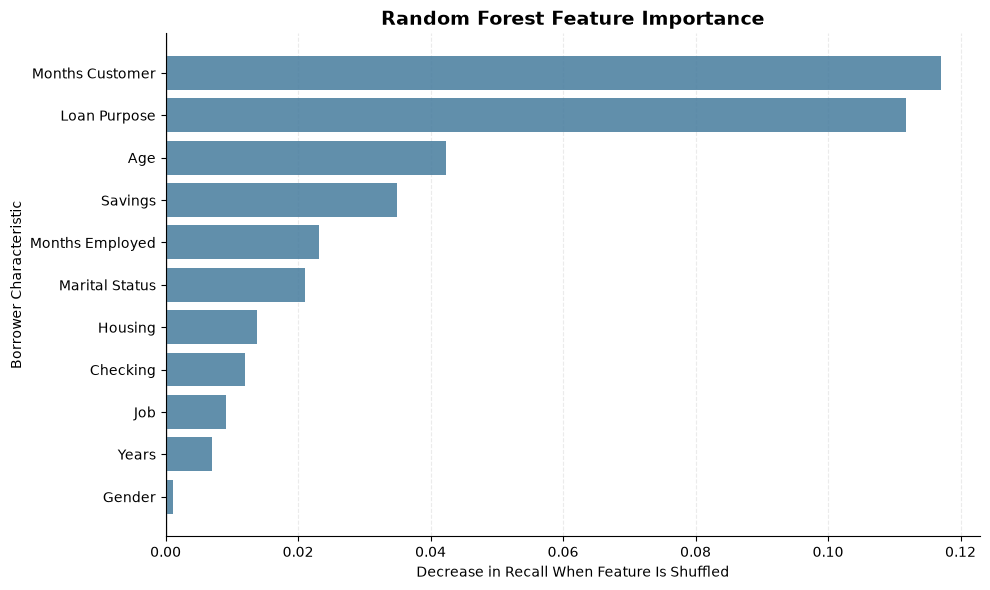

In [8]:
# === Random Forest Feature Importance ===

from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# Measure importance using the training dataset
# This preserves our test dataset for final evaluation
importance_results = permutation_importance(
    random_forest_model,
    X_train,
    y_train,
    n_repeats=10,              # Shuffle each feature 10 times
    random_state=42,
    scoring="recall_macro"     # Evaluate recall across both risk classes
)

# Create a table of feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_results.importances_mean
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("=== Random Forest Feature Importance ===")
display(feature_importance.round(4))

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color="#457B9D",
    alpha=0.85
)

ax.invert_yaxis()

ax.set_title(
    "Random Forest Feature Importance",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Decrease in Recall When Feature Is Shuffled")
ax.set_ylabel("Borrower Characteristic")

ax.axvline(0, color="gray", linewidth=1)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Random Forest Feature Importance**

Customer relationship duration (Months Customer) and Loan Purpose are the two most important features in the Random Forest model, with importance scores of 0.1171 and 0.1118, respectively.

Age, Savings, and Months Employed contribute to the model's predictions, but their importance scores are considerably lower.

It is interesting that Months Customer ranks first because our earlier exploratory analysis and chi-square test also identified a strong association between customer relationship duration and credit risk.

Checking balance has relatively low importance, which is consistent with the unclear patterns we observed during EDA.

Overall, customer relationship duration and loan purpose appear to be particularly useful for predicting credit risk in this dataset. However, these results are based on training data, so they should be interpreted as exploratory rather than definitive.

## 5.5 Final Model Evaluation and Overfitting Check

In [9]:
# === Final Model Evaluation ===

from sklearn.metrics import accuracy_score, recall_score

# Store our two trained models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

# Evaluate each model on training and testing data
for name, model in models.items():

    # Generate predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Calculate performance metrics
    train_accuracy = accuracy_score(y_train, train_predictions)
    test_accuracy = accuracy_score(y_test, test_predictions)

    train_recall = recall_score(
        y_train, train_predictions, pos_label="High"
    )
    test_recall = recall_score(
        y_test, test_predictions, pos_label="High"
    )

    # Store results for comparison
    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Train High Risk Recall": train_recall,
        "Test High Risk Recall": test_recall
    })

# Create comparison table
model_comparison = pd.DataFrame(results).set_index("Model")

print("=== Final Model Comparison ===")
display((model_comparison * 100).round(1))

=== Final Model Comparison ===


,Train Accuracy,Test Accuracy,Accuracy Gap,Train High Risk Recall,Test High Risk Recall
Model,,,,,
Logistic Regression,69.7,63.5,6.2,68.0,61.9
Random Forest,100.0,67.1,32.9,100.0,73.8


**Observation: Model Evaluation and Overfitting**

Logistic Regression achieved 69.7% training accuracy and 63.5% testing accuracy, showing a relatively small performance gap.

Random Forest achieved 100% training accuracy but only 67.1% testing accuracy, resulting in a much larger gap of 32.9 percentage points.

Although Random Forest performed better on the test dataset, the large difference between training and testing performance suggests substantial overfitting.

Random Forest also achieved higher High Risk recall (73.8%) compared with Logistic Regression (61.9%).

Random Forest appears more effective at identifying high-risk borrowers, but its overfitting needs to be addressed before selecting it as our final model.

In [11]:
# === Random Forest: Overfitting Reduction ===
# max_depth=5 prevents trees from becoming excessively complex
# min_samples_leaf=5 prevents the model from creating rules based on just one or two borrowers

# Create a more controlled Random Forest model
tuned_rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,           # Limit how deep each tree can grow
        min_samples_leaf=5,    # Require at least 5 borrowers per leaf
        class_weight="balanced",
        random_state=42
    ))
])

# Train the new model
tuned_rf_model.fit(X_train, y_train)

# Generate predictions
tuned_train_predictions = tuned_rf_model.predict(X_train)
tuned_test_predictions = tuned_rf_model.predict(X_test)

# Compare training and testing performance
print("=== Controlled Random Forest Results ===")

print(
    "Training Accuracy:",
    round(accuracy_score(y_train, tuned_train_predictions) * 100, 1),
    "%"
)

print(
    "Testing Accuracy:",
    round(accuracy_score(y_test, tuned_test_predictions) * 100, 1),
    "%"
)

print(
    "Testing High Risk Recall:",
    round(
        recall_score(
            y_test,
            tuned_test_predictions,
            pos_label="High"
        ) * 100,
        1
    ),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, tuned_test_predictions))

=== Controlled Random Forest Results ===
Training Accuracy: 81.5 %
Testing Accuracy: 69.4 %
Testing High Risk Recall: 69.0 %

Classification Report:
              precision    recall  f1-score   support

        High       0.69      0.69      0.69        42
         Low       0.70      0.70      0.70        43

    accuracy                           0.69        85
   macro avg       0.69      0.69      0.69        85
weighted avg       0.69      0.69      0.69        85



**Observation: Random Forest Overfitting Reduction**

Limiting tree depth and requiring at least five borrowers per leaf reduced training accuracy from 100% to 81.5%.

Testing accuracy improved from 67.1% to 69.4%, while the training-testing accuracy gap decreased from 32.9 to 12.1 percentage points.

High Risk recall decreased slightly from 73.8% to 69.0%, but High Risk precision improved from approximately 64.6% to 69.0%.

The controlled Random Forest shows a better balance between training and testing performance, although there is still room for improvement.

Overall, controlling model complexity helped reduce overfitting. The results also demonstrate the trade-off between identifying more high-risk borrowers and reducing incorrect high-risk classifications.

## 5.7 Cross-Validation and Model Selection

In [13]:
# === 5-Fold Cross-Validation ===

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

# Models we want to compare
models = {
    "Logistic Regression": logistic_model,
    "Original Random Forest": random_forest_model,
    "Controlled Random Forest": tuned_rf_model
}

# Divide training data into 5 groups
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate accuracy and recall specifically for High Risk
scoring = {
    "Accuracy": "accuracy",
    "High Risk Recall": make_scorer(
        recall_score,
        pos_label="High"
    )
}

results = []

# Evaluate each model using cross-validation
for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "CV Accuracy (%)": scores["test_Accuracy"].mean() * 100,
        "CV High Risk Recall (%)": scores["test_High Risk Recall"].mean() * 100,
        "CV Accuracy Std (%)": scores["test_Accuracy"].std() * 100
    })

# Display the comparison
cv_results = pd.DataFrame(results).set_index("Model")

print("=== 5-Fold Cross-Validation Results ===")
display(cv_results.round(2))

=== 5-Fold Cross-Validation Results ===


,CV Accuracy (%),CV High Risk Recall (%),CV Accuracy Std (%)
Model,,,
Logistic Regression,62.94,62.66,3.88
Original Random Forest,59.12,59.71,4.10
Controlled Random Forest,60.88,59.77,3.17


**Observation: Cross-Validation and Model Selection**

Logistic Regression achieved the highest average cross-validation accuracy (62.94%) and High Risk recall (62.66%) among the three models.

Although Random Forest performed better on the original test set, its cross-validation results were weaker, suggesting that its performance may depend on the particular training and testing split.

The controlled Random Forest had the lowest variation in accuracy across folds, but it did not outperform Logistic Regression on average.

Based on these results, Logistic Regression was selected as the final model for this project.

The model provides a useful starting point for credit risk prediction, but its moderate performance means predictions should be interpreted cautiously and not used as the sole basis for lending decisions.

## 5.8 Credit Risk Predictions for New Borrowers

In [14]:
# === Predict Credit Risk for 10 Additional Borrowers ===

# Load the additional dataset from the second Excel sheet
additional_df = pd.read_excel(file_path, sheet_name=1)

# Apply the same basic cleaning used for training
additional_df.columns = additional_df.columns.str.strip()
additional_df["Gender"] = additional_df["Gender"].str.strip().str.upper()

# Select exactly the same input features used during training
X_new = additional_df[X.columns]

# Predict credit risk using our selected Logistic Regression model
predicted_risk = logistic_model.predict(X_new)

# Get the probability of High Risk for each borrower
# Find the correct probability column using the model's class labels
high_risk_index = list(
    logistic_model.named_steps["classifier"].classes_
).index("High")

high_risk_probabilities = (
    logistic_model.predict_proba(X_new)[:, high_risk_index]
)

# Create a separate results table
prediction_results = additional_df.drop(
    columns=["Credit Risk"]
).copy()

# Add an identifier for each borrower
prediction_results.insert(
    0, "Borrower ID", range(1, len(prediction_results) + 1)
)

# Add model predictions
prediction_results["Predicted Credit Risk"] = predicted_risk
prediction_results["High Risk Probability (%)"] = (
    high_risk_probabilities * 100
).round(1)

# Display a summary of the predictions
print("=== Credit Risk Predictions for New Borrowers ===")

display(
    prediction_results[
        [
            "Borrower ID",
            "Loan Purpose",
            "Months Customer",
            "Predicted Credit Risk",
            "High Risk Probability (%)"
        ]
    ]
)

=== Credit Risk Predictions for New Borrowers ===


c:\Users\selen\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,Borrower ID,Loan Purpose,Months Customer,Predicted Credit Risk,High Risk Probability (%)
0,1,Education,30,High,61.4
1,2,Business,15,Low,48.4
2,3,New Car,15,High,52.9
3,4,Furniture,10,Low,27.5
4,5,Small Appliance,10,Low,36.5
5,6,Business,8,Low,36.5
6,7,Education,50,High,83.0
7,8,Retraining,20,Low,41.2
8,9,Small Appliance,12,Low,24.9
9,10,Repairs,25,High,70.7


**Observation: Credit Risk Predictions for New Borrowers**

The final Logistic Regression model classified 4 of the 10 additional borrowers as High Risk and 6 as Low Risk.

Borrower 7 had the highest estimated High Risk probability at 83.0%, followed by Borrower 10 at 70.7%.

Borrower 3 was classified as High Risk with a probability of 52.9%, showing that some predictions are closer to the classification threshold than others.

These results demonstrate how predictive modeling can support customer risk analysis, but the model's moderate accuracy means the predictions should be interpreted cautiously.

The results will be included in the Power BI dashboard to demonstrate how historical customer information can be used to explore potential credit risk.

In [15]:
# === Export Data for Power BI ===

from pathlib import Path

# Create a folder for dashboard-ready data
output_folder = Path("Dashboard_Data")
output_folder.mkdir(exist_ok=True)

# Export historical borrower data
base_df.to_csv(
    output_folder / "historical_borrowers.csv",
    index=False
)

# Export predictions for the 10 additional borrowers
prediction_results.to_csv(
    output_folder / "new_borrower_predictions.csv",
    index=False
)

print("=== Power BI Data Export Complete ===")
print("Historical borrowers:", len(base_df))
print("New borrower predictions:", len(prediction_results))
print("Files saved in:", output_folder)

=== Power BI Data Export Complete ===
Historical borrowers: 425
New borrower predictions: 10
Files saved in: Dashboard_Data


In [16]:
# Export Logistic Regression test results for Power BI
import pandas as pd

model_test_results = pd.DataFrame({
    "Actual Credit Risk": y_test.to_numpy(),
    "Predicted Credit Risk": logistic_predictions
})

model_test_results.to_csv(
    "Dashboard_Data/model_test_results.csv",
    index=False
)

print(model_test_results.head())
print(f"Total test borrowers: {len(model_test_results)}")

  Actual Credit Risk Predicted Credit Risk
0                Low                   Low
1                Low                   Low
2               High                   Low
3               High                  High
4                Low                  High
Total test borrowers: 85


In [17]:
# Export model comparison results for Power BI
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Random Forest",
        "Controlled Random Forest"
    ],
    "CV Accuracy (%)": [62.94, 59.12, 60.88],
    "CV High-Risk Recall (%)": [62.66, 59.71, 59.77],
    "CV Accuracy Std (%)": [3.88, 4.10, 3.17]
})

model_comparison.to_csv(
    "Dashboard_Data/model_comparison.csv",
    index=False
)

display(model_comparison)

,Model,CV Accuracy (%),CV High-Risk Recall (%),CV Accuracy Std (%)
0,Logistic Regression,62.94,62.66,3.88
1,Original Random Forest,59.12,59.71,4.10
2,Controlled Random Forest,60.88,59.77,3.17
